## Imports:

In [81]:
%load_ext autoreload
%autoreload 2

import os
import sys
import random
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

from knowledge_maze.tools.utils import load_json, load_jsonl, display_usage_log
from knowledge_maze.create_dataset.create_questions.wikipedia_mining import WikiMiner
from knowledge_maze.create_dataset.create_questions.table_processing import AsyncWikiExtractor, TablePostProcessor
from knowledge_maze.create_dataset.create_questions.grouping_entities import TableGroupConstructor, GroupValidator
from knowledge_maze.create_dataset.create_questions.question_generation import TableSanitizer, StrategySelector, QuestionGenerator, QuestionFilter
from knowledge_maze.create_dataset.create_questions.question_validator import ManualTagger
from knowledge_maze.create_dataset.create_answers.answer_orchestrator import AnswerGenerator
from knowledge_maze.create_dataset.create_answers.answer_qa_tagger import AnswerValidityTagger
from knowledge_maze.create_dataset.create_context.paragraph_pipeline import ContextPipeline
from knowledge_maze.create_dataset.data_annotation.data_statistics import KnowledgeConflictDatasetStats

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [103]:
# Display Open Router usage log: 
display_usage_log()

Open Router all time usage cost: 33.058$
Daily usage:
 - 2026-04-09: 0.023$
 - 2026-04-10: 0.061$
 - 2026-04-11: 1.092$
 - 2026-04-12: 0.092$
 - 2026-04-13: 1.658$
 - 2026-04-14: 0.027$
 - 2026-04-15: 2.356$
 - 2026-04-18: 6.713$
 - 2026-04-19: 2.713$
 - 2026-04-20: 5.130$
 - 2026-04-21: 1.549$
 - 2026-04-22: 3.047$
 - 2026-04-23: 2.253$
 - 2026-04-24: 6.343$


# Data Creation:
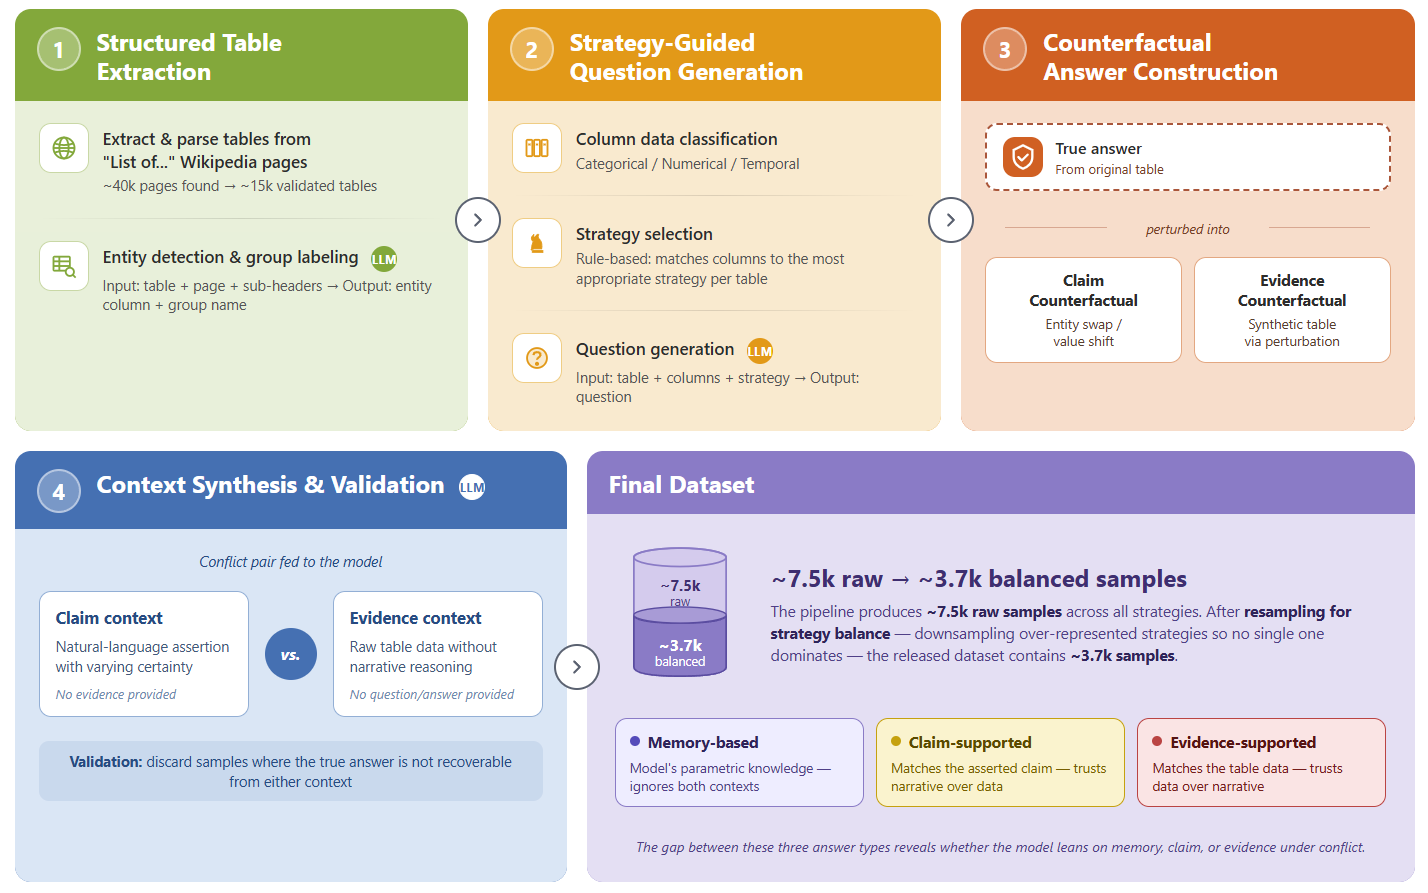

# 1. Structured Table Extraction:

## 1.1 Harvest Wikipedia pages with tables:

1. **The Discovery Phase (The Wide Net)**
   - Input: 22 Subject Groups (e.g., Infrastructure, Sports).
   - Action: We hit the Wikipedia API with two distinct patterns:
     - Prefix Mining: Grabbing every page starting with "Entity in/of..."
     - Search Mining: Finding every page with "List of [Entity]" in the title.
     - Goal: Maximum recall. We want to find everything that might be a list.
2. **The Validation Phase (The Filter)**
   - Action: We open every page found in Phase 1 (asynchronously for speed).
   - Logic: We look for the "DNA" of a table: the {| or wikitable tags.
   - Outcome: We discard the "stub" articles or prose-only pages that don't actually contain structured data.
3. **The Clustering Phase (The De-duplicator)**
   - Problem: Wikipedia often has "List of 2023 Films" and "List of films of 2023." These are duplicates.
   - Action: Using TF-IDF to cluster similar page titles.
   - If two titles are >80% similar, we draw a line (edge) between them.
   - Pick a representative from each cluster to continue.

In [12]:
miner = WikiMiner()
await miner.extract()

Mining Pages:   0%|          | 0/320 [00:00<?, ?entity/s]

Filtering Pages with Tables:   0%|          | 0/89666 [00:00<?, ?page/s]

Computing Similarities for 43937 Titles:   0%|          | 0/43937 [00:00<?, ?titles/s]

Picking Representatives from 39391 Clusters:   0%|          | 0/39391 [00:00<?, ?cluster/s]

## 1.2. Parse and filter valid Wikipedia tables:

1. **Geometric Fix** - Rebuilds the "hidden grid" of the table. It maps merged cells (rowspans) to their correct spots so the data doesn't shift.
2. **Context Grab** - Captures the Section Path (e.g., Earthquakes > 1954) and the Intro Sentence above the table to explain what the data means.
3. **Trash Filter** - Deletes "Legend" tables, empty tables, and tiny snippets. If it's less than 4 rows or 50% empty, it’s gone.
4. **Variety Control** - "Detects ""Clones"" (like 12 identical monthly tables). It keeps a maximum of 4 different tables per page to ensure the dataset isn't boring.

In [151]:
extractor = AsyncWikiExtractor(output_file=os.path.join(REPO_PATH, "data_files/intermediate_files/candidate_tables.jsonl"))
validated_tables_file_name = await extractor.run_with_progress(load_json(os.path.join(REPO_PATH, "data_files/valid_titles.json")))

processor = TablePostProcessor(os.path.join(REPO_PATH, "data_files/intermediate_files/candidate_tables.jsonl"))
cleaned_data = processor.process()

Filtering & Cleaning:   0%|          | 0/64646 [00:00<?, ?it/s]

Legend / Key Filter,553
Header Parsing Failures,"3,883"
Cell Content Too Long,"1,936"
Malformed Row Structures,"1,603"
Alphabetical Lists Removed,639
Tables with no Headers,585
Long Tables Removed,"31,673"
Intra-Page Duplicates Removed,"8,883"


In [5]:
processor.display_sample()

,Order,Grand Finalist,Age,Winner of Episode...,Appeared as,Performing,Total score,Place
0,1,Lewis Devine,14,1 (21 July 2001),Donny Osmond,""" The Twelfth of Never """,35411,5th
1,2,Louise Emmanuel,16,3 (7 September 2002),Irene Cara,"""Fame""",25096,6th
2,3,Charlotte Gethin,14,2 (31 August 2002),Eva Cassidy,"""Over the Rainbow""",282422,1st
3,4,Porsha Mavour,10,5 (21 September 2002),Millie Small,"""My Boy Lollipop""",79674,3rd
4,5,Amanda Tinkler,16,4 (14 September 2002),Nelly Furtado,"""I'm Like A Bird""",55638,4th
5,6,Russell Parsons,16,6 (28 September 2002),Robbie Williams,"""Let Me Entertain You""",142887,2nd


## 1.3. Create Potential Entity Groups:

A table is considered a valid **entity group** if it satisfies the following conditions:

- **Entity Column:** The table must contain a column where each cell is a unique instance of the same entity type (e.g., person, film, city, team).
- **Subject Over Data:** The group name must describe **what the rows are**, not attributes or statistics about them.
- **Entity–Name Alignment:** The group name must accurately match the type of entities in the entity column.
- **No Repeated Labels:** The entity column cannot contain generic labels or repeated categories (e.g., "Height", "Weight").
- **No Summary Tables:** Tables that summarize metrics (e.g., "Total Population", "Revenue") rather than listing entities are invalid.
- **Clear Grouping Rule:** The group must explain why these entities appear together (e.g., *Top 10 films by revenue*, *Citrus fruits*).
- **Closed and Coherent Set:** The rows cannot be a random subset of a larger category unless a clear filter exists (e.g., ranking, time constraint).
- **Member Consistency:** All entities must logically belong to the group definition.
- **Specific Category:** The group must use precise and objective definitions; vague terms like "famous" or "important" are not allowed.
- **Natural Category:** The grouping must reflect a meaningful category that humans would reasonably recognize.
- **Context Usage:** Headers, captions, and nearby text may be used to refine the group definition when informative.
- **Conservative Validation:** If the grouping logic is unclear or ambiguous, the table should be rejected.


In [86]:
cleaned_data = load_jsonl(os.path.join(REPO_PATH, "data_files/intermediate_files/candidate_tables.jsonl"))
group_constructor = TableGroupConstructor(random.sample(cleaned_data, 100))
await group_constructor.get_groups()

Creating 100 Entity Groups:   0%|          | 0/100 [00:00<?, ?it/s]

Duplicate Entities Found,16
LLM Rejected,12
Entity Column has Numeric/Date Values,4
Kill-List Keywords in Group Name,1
Empty Entity Cells,1


In [213]:
group_constructor.display_debug_samples()

### Validate a small subset using Gemini 3.1 pro:

### RULES FOR VALIDITY

1. **FATEFULNESS:** Members must logically match the Group Name. Reject if the description is misleading, overly broad, or contains unrelated concepts.
2. **CLOSED_SET:** The group must be coherent and complete. Reject random subsets (e.g., "6 random cities in France"). 
   *Exception:* Specific filters (e.g., "Top 10", "Oldest 5", "Members in 2024") are valid.
3. **SPECIFICALITY:** The group must have a narrow, clear concept. Reject vague names like "Famous movies" or "Important countries."
4. **NATURALNESS:** The category must be one that humans would reasonably group together. Reject arbitrary rules (e.g., "Cities starting with Q that have 3 vowels").
5. **CORRECT_ENTITY:** The Entity Column must contain the primary entities, not metadata (Rank, Year, ID) or attributes.

In [354]:
group_val = GroupValidator(random.sample(group_constructor.valid_tables, 200))
await group_val.validate()

Evaluating Group Samples:   0%|          | 0/200 [00:00<?, ?it/s]

"● CLOSED_SET 2 Children's animated television series from the United Kingdom released in the 2010s The group contains only 7 entities, which is an incomplete subset of all UK children's animated television series released in the 2010s (missing notable shows like Octonauts, Bing, and Danger Mouse)."
"● CORRECT_ENTITY 1 Club captains of Kerala Blasters FC The entity column contains multiple names concatenated together without delimiters (e.g., 'Iain Hume David James Cédric Hengbart Penn Orji'), indicating a parsing error rather than clean individual entities."
"● FATEFULNESS 2 Eastern Catholic eparchs of American eparchies immediately subject to the Holy See The entity list includes 'Sede Vacante', which is a Latin term for a vacant seat, not an actual person or eparch, making the members logically inconsistent with the group name."
"● NATURALNESS 3 Top 6 Caribbean islands with an area between 10 and 29 km2 The group is defined by an arbitrary area range (between 10 and 29 km2) and an arbitrary limit (Top 6), which does not form a natural or meaningful category."


# 2. Strategy-Guided Question Generation:

## 2.1. Select Preferred Question Strategies for each Entity Group:

**1. Table Sanitizer - Clean the noise and infer data types:**
   - Ref-Stripping: Removes Wikipedia footnotes (e.g., [1], [a]) and fuzzy prefixes (~, >, approx).
   - Unit Validation: Only treats strings as numbers if they match VALID_METRICS (kg, m, %, $) to avoid "5 dogs" being indexed as a float.
   - Auto-Scaling: Converts "1.2 billion" into 1,200,000,000 automatically.Trash Filtering: Prunes metadata columns (Rank, Notes, Index) and low-density columns (>50% empty).

**2. Strategy Selection - Determine the most "natural" questions for each table:**
   - Outlier Detection: Boosts EXTREME_NUMERICAL if a value is $> 2\times$ the column mean.
   - Clump Analysis: Triggers FILTER_COUNT or FREQUENCY_MODE if values repeat (e.g., multiple items from the same "Category").
   - Temporal Heuristics: Identifies years (1000–2100) to pivot toward "Earliest/Latest" logic.
   - Entity Guardrail: Discards tables where the subject column is purely numeric or contains nulls.

**3. Quality Scoring & Slicing - Final validation and data reduction:**
   - The 0.45 Threshold: Strategies must score $> 0.45$ to be considered "interesting" enough for the dataset.
   - Data Slicing: Generates "Strategy Views"—minimal sub-tables containing only the columns required for the chosen question type.
   - Triviality Check: Blocks "Count" questions if the count is already leaked in the table title (e.g., "Top 10...").

In [87]:
selector = StrategySelector(load_json(os.path.join(REPO_PATH, "data_files/intermediate_files/valid_groups.json")))
selector.get_strategies()

Sanitizing tables:   0%|          | 0/679 [00:00<?, ?it/s]

Slicing strategy views:   0%|          | 0/679 [00:00<?, ?it/s]

Strategy Name,Selection Count
COUNT_TOTAL,362
EXTREME_TEMPORAL,304
FILTER_COUNT_TEMPORAL,211
UNIQUE_DIVERSITY,198
FREQUENCY_MODE,157
CATEGORICAL_FILTER_LOOKUP,149
COMPARATIVE_DIFFERENCE,130
EXTREME_NUMERICAL,124
TOP_K_RANKING,117
FILTER_COUNT_NUMERICAL,96


In [88]:
selector.debug_strategy_samples("CATEGORICAL_FILTER_LOOKUP")

Name,City/Town
Indore Museum,Indore
Bharat Bhavan,Bhopal
Museum of Mankind(Manav Sangrahalaya),Bhopal
"State Museum, Bhopal",Bhopal
Tribal Museum Bhopal,Bhopal
"Regional Museum of Natural History, Bhopal",Bhopal
"Regional Science Centre, Bhopal",Bhopal
Maharaja Chhatrasal Museum,Dhubela
Gujari Mahal Archaeological Museum,Gwalior
Sanchi Archaeological Museum,Sanchi


## 2.2. Create Complex Reasoning Questions w.r.t. Entity Groups & Selected Strategies:

**1. Question Generation - Transform raw table data into natural, human-sounding questions:**
   - The "Radio Test": Questions must be self-contained. If a listener heard it on the radio, they should understand exactly what is being discussed without seeing the table.
   - Anti-AI Phrases: Strictly prohibits "According to the table" or "Based on the data." It uses a Prohibited List to force natural journalistic flow.
   - Strategy Leveling: If a table has 4 possible strategies, the generator prioritizes the one that has been "starved" (tried the least globally) to ensure a diverse dataset.
   - Subset Identification: Instead of saying "these rows," the model must identify the shared trait (e.g., "The six MLB players who...") to define the scope.

**2. Quality & Deduplication - Final audit to ensure the dataset is unique and structurally perfect:**
   - Schema Enforcement: Rejects any question where the table view accidentally contains extra columns or missing data.
   - Fuzzy Deduplication: Uses rapidfuzz to find questions that are $>85\%$ similar. If two questions are nearly identical, it keeps the one with the rarest strategy to preserve variety.
   - Strict Null Check: Any "empty" or "null" response from the LLM is immediately caught and logged as a failure.The Rarity Tie-Breaker: When two tables produce the same question (e.g., "Who won the game?"), the system checks which strategy is less common in the overall pool and saves that one.

In [80]:
generator = QuestionGenerator(selector.updated_data, strategy_definitions=load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json")))
await generator.generate_questions()

Round 1 - Processing 120 tables to questions:   0%|          | 0/120 [00:00<?, ?it/s]

Round 2 - Processing 6 tables to questions:   0%|          | 0/6 [00:00<?, ?it/s]

Round 3 - Processing 1 tables to questions:   0%|          | 0/1 [00:00<?, ?it/s]

Round 4 - Processing 1 tables to questions:   0%|          | 0/1 [00:00<?, ?it/s]

Strategy Name,Success,Tried,Rate
COUNT_TOTAL,25,25,100%
CATEGORICAL_FILTER_LOOKUP,16,17,94%
FILTER_COUNT_TEMPORAL,15,15,100%
UNIQUE_DIVERSITY,15,15,100%
FREQUENCY_MODE,15,16,94%
EXTREME_TEMPORAL,15,16,94%
AGGREGATION,5,7,71%
EXTREME_NUMERICAL,4,4,100%
FILTER_COUNT_NUMERICAL,4,5,80%
TOP_K_RANKING,3,5,60%


In [360]:
val = QuestionFilter(generator.valid_results)
val.run_pipeline()

Starting post-processing with 642 samples...


Rule,Definition,Count
FORBIDDEN_KEYWORD,A forbidden keyword was found in the question text.,31
DUPLICATE_DATA,Question is too similar to another question in the dataset.,23
EXTRA_COLUMNS,Table contains more than one attribute column (schema violation).,1
MISSING_QUESTION,Question field was empty or null.,0
MISSING_TABLE,No table data was found for this sample.,0
MISSING_COLUMNS,Table lacks an attribute column for this strategy.,0
EMPTY_DATA,Attribute column exists but has no data rows.,0


In [33]:
question_data = load_json(os.path.join(REPO_PATH, "data_files/intermediate_files/question_dataset.json"))

In [342]:
tagger = ManualTagger(question_data, load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json")))
tagger.display()

📦 Progress Loaded: 210 samples already tagged in 'tagger_progress.json'.


Output()

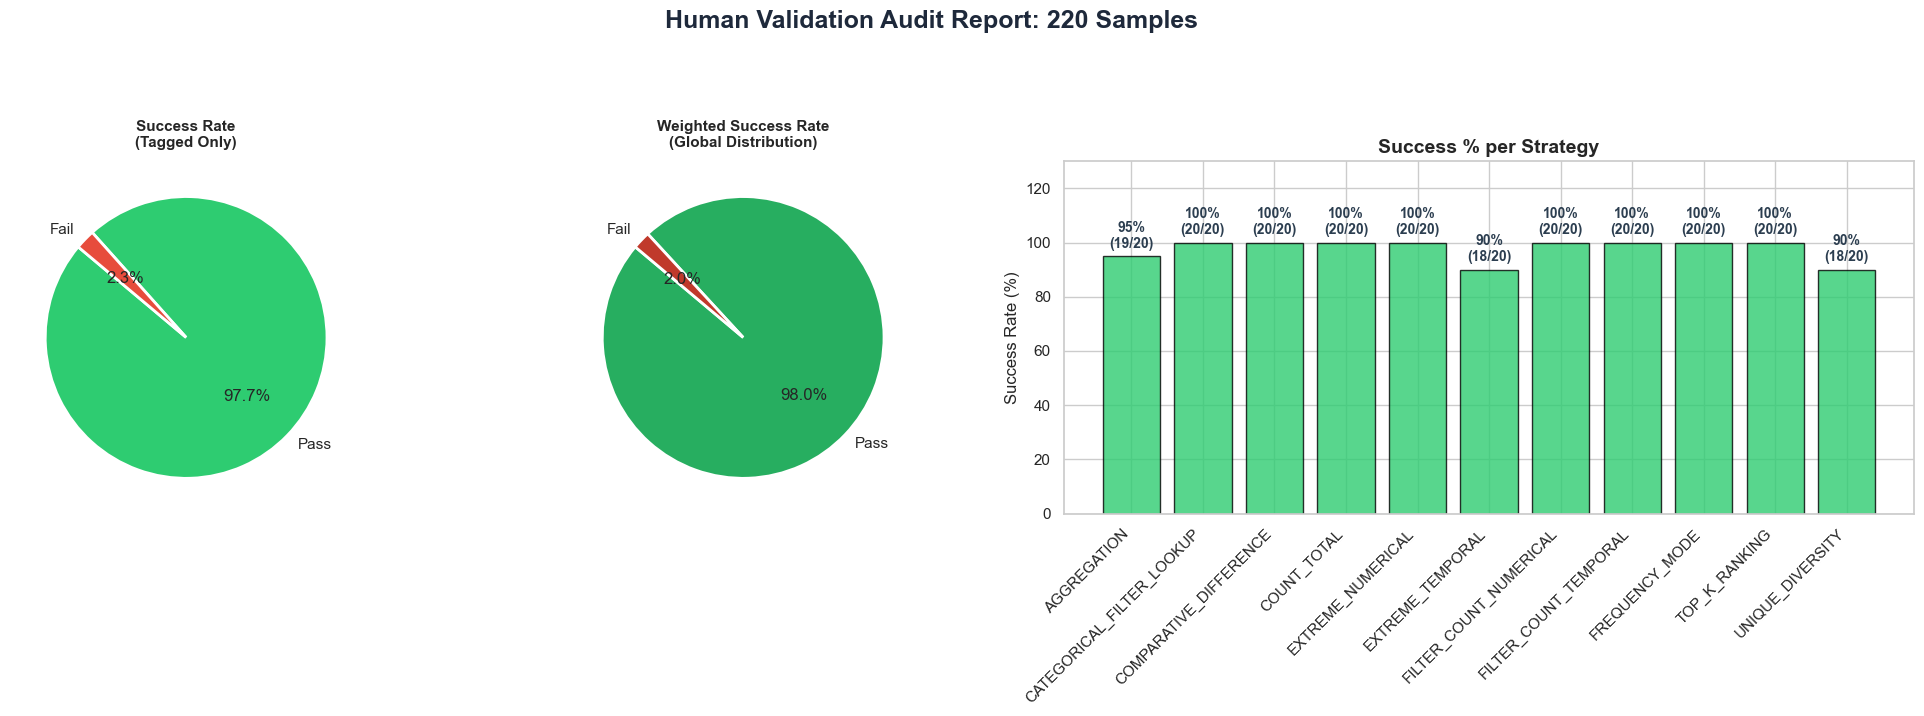

In [343]:
tagger.plot_results()

# 3. Counterfactual Answer Construction:

The core philosophy of this system moves beyond simple "wrong" answers. Instead, we engineer **plausible traps** and **manufactured realities**. This rigorously tests whether an LLM is genuinely reasoning through the provided data or merely relying on pre-trained memory and statistical guessing.

---

The strategy relies on two interconnected pillars to challenge the model's logic:

### 1. Adversarial Answer Generation (The "Trap")
To make a distractor compelling, it must be indistinguishable from a correct answer at a glance. We achieve this through **targeted perturbations**:

* **Mathematical Traps** - We calculate the true answer and apply common human or mechanical errors, such as **off-by-one nudges**, operation swapping (addition vs. subtraction), or alternative plausible counts.
* **Entity & Value Swapping** - We substitute correct names, dates, or categories with other valid entities from the same dataset. This ensures the fake answer uses the correct vocabulary and format, bypassing simple string-matching heuristics.
* **Boundary Scaling** - For questions involving extremes (Maximums/Minimums), we take the true value and scale it slightly. This creates a highly believable "near-miss" distractor.

---

### 2. Evidence Manipulation (The "Fake Reality")
A tricky answer is only half the battle. To truly test an LLM’s adherence to context, we provide a **"lied" version** of the source table where the fake answer is technically correct.

* **Targeted Nudges** - We subtly alter specific numbers, shift dates, or merge categories within the table so that the adversarial math or count becomes technically accurate according to the modified text.
* **Structural Shifting** - We drop specific rows, artificially inflate the frequency of certain items, or shuffle values between entities. This invalidates the original reasoning path and crowns a new, factually incorrect "winner."
* **Knowledge Conflict Engineering** - By pairing a fake answer with a structurally manipulated table that supports it, we force the LLM into a conflict. The model must choose: **Does it trust its pre-trained factual knowledge, or the strict, altered reality of the provided prompt?**

In [105]:
question_data = load_json(os.path.join(REPO_PATH, "data_files/intermediate_files/question_dataset.json"))
generator = AnswerGenerator()
generator.process_dataset(question_data)

Reasoning Strategy,Passed,Rejected
COUNT_TOTAL,145,0
AGGREGATION,18,0
EXTREME_NUMERICAL,32,0
TOP_K_RANKING,33,0
CATEGORICAL_FILTER_LOOKUP,50,1
FILTER_COUNT_NUMERICAL,27,5
COMPARATIVE_DIFFERENCE,33,1
UNIQUE_DIVERSITY,39,0
FREQUENCY_MODE,47,0
EXTREME_TEMPORAL,76,0


In [6]:
answer_tagger = AnswerValidityTagger(load_json(os.path.join(REPO_PATH, "data_files/intermediate_files/question_answer_dataset.json")), 
                                     load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json")))
answer_tagger.display()

📦 Progress Loaded: 134 answer samples already tagged in 'answer_tagger_progress.json'.


Output()

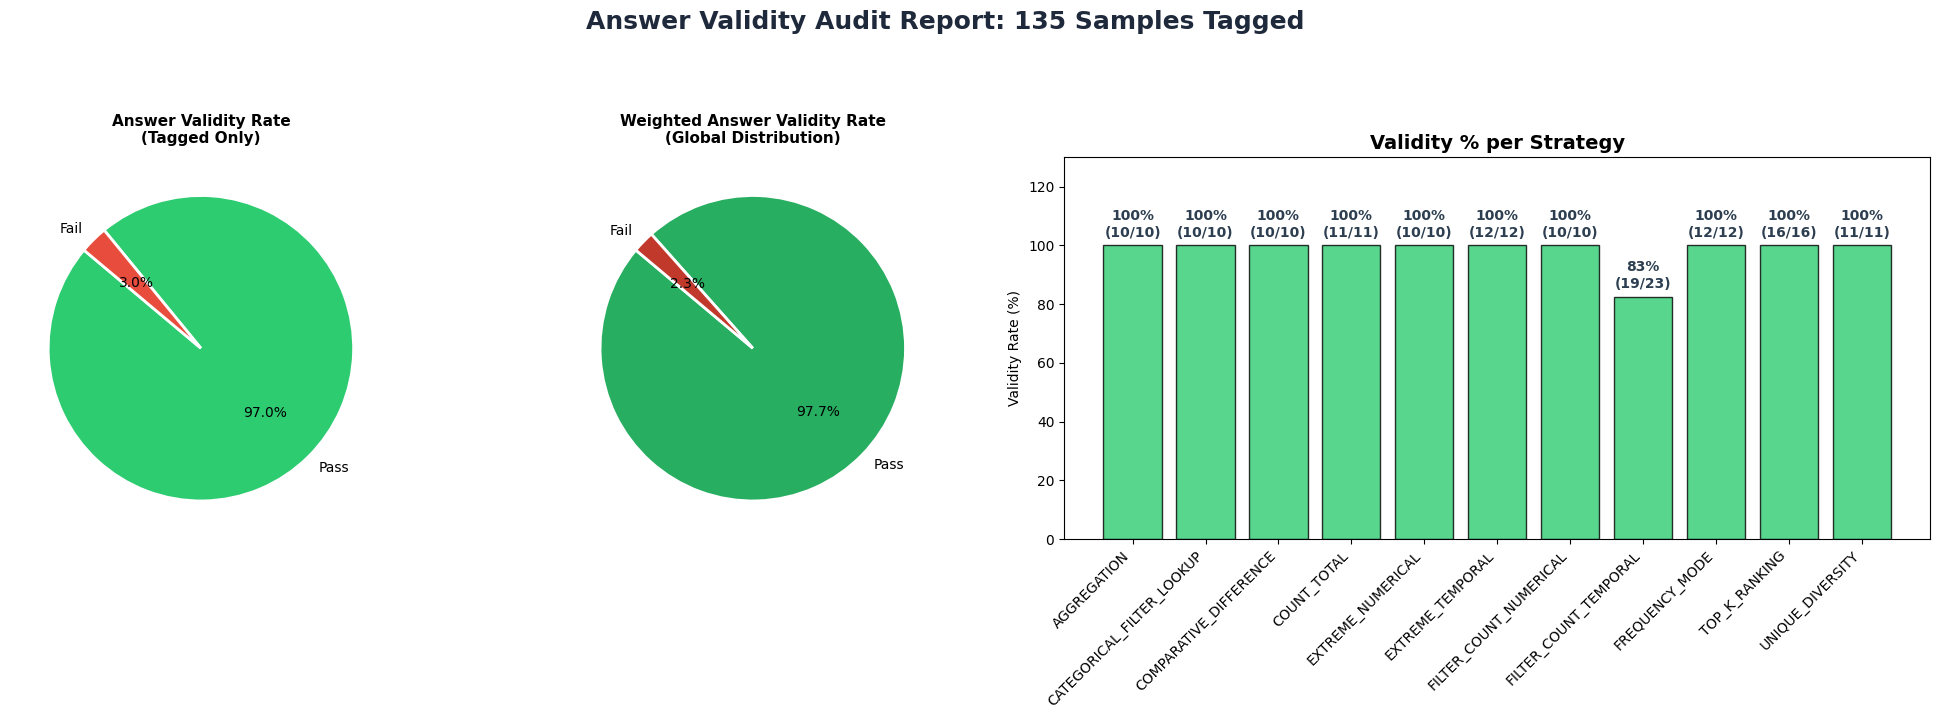

In [7]:
answer_tagger.plot_results()

# 4. Context Synthesis & Validation:

### 🛰️ Phase 1: Evidence Paragraphs
The objective is to convert raw data into an authoritative, prose-based "Ground Truth."

* **Persona-Driven Narratives:** We use specialized personas to ensure the tone matches the data type (e.g., treating numbers as "physical constants").
* **Closed-Set Authority:** The text is engineered to establish itself as an exhaustive source. It explicitly states that no other entities exist beyond what is written, preventing the model from hallucinating external knowledge.
* **Numeric Fidelity:** Every decimal point and currency symbol is preserved exactly as a string, ensuring the truth remains immutable and preventing the generation model from "rounding" the data.

---

### 📍 Phase 2: Claim Paragraphs
Once the evidence is set, we create the "entry point" for the user's question—the Claim Paragraph.

* **The "Abstract Haystack":** The target answer is buried within 150-200 words of high-level, conceptual filler. This text is strictly abstract (philosophical or methodological) to ensure zero data leakage.
* **Epistemic Variation:** We inject **certainty markers** (High, Medium, and Low). This allows us to evaluate if a model can distinguish between a "Verified Fact" and "Whispers/Speculation."
* **Strategic Placement:** The claim is placed at the start, middle, or end of the paragraph to test the model's ability to retrieve information regardless of its position in the context.

---

### 🛡️ Phase 3: Adversarial Validation (The Quality Gate)
The most critical step in the pipeline is the LLM-as-a-Judge validation loop. We don't just generate data; we audit its solvability. We exclude instances that are not consistently solvable under direct-answer prompting, ensuring that all evaluated prompting strategies operate under equal capability conditions. This prevents confounding improvements due to output structuring from influencing the analysis of conflict resolution behavior. We use a specialized **LLMValidator** to put every sample through a multi-stage "stress test" before it is approved for the final dataset.

---

### 🎭 Phase 4: Distractor Synthesis & Noise Injection
To ensure the benchmark measures active reasoning rather than simple keyword matching, we surround the evidence with high-fidelity, adversarial distractors.

* **Semantic Proximity (TF-IDF Scaling):** We avoid random "placeholder" text. Instead, we utilize a Parallel Distractor Sweep powered by TF-IDF vectorization to identify paragraphs that share the same entities, terminology, and themes as the target question. This creates a "conceptual mirror" that forces the model to perform precise data extraction rather than shallow scanning.
* **Adversarial Filtering (The Leakage Sweep):** Every potential distractor is audited by an asynchronous LLM-as-a-Judge. If a distractor accidentally contains information that could answer the target question, it is purged. This ensures the distractors are "Safe Noise"—mathematically relevant but factually empty regarding the specific query.

In [106]:
question_answer_dataset = load_json(os.path.join(REPO_PATH, "data_files/intermediate_files/question_answer_dataset.json"))
pipeline = ContextPipeline()
await pipeline.run(question_answer_dataset)

[*] Stage 1: Evidence Generation for 577 samples...


Generating Evidence Paragraphs:   0%|          | 0/577 [00:00<?, ?it/s]

Error: Token limit reached.
Error: Token limit reached.
Error: Token limit reached.
Error: Token limit reached.
Error: Token limit reached.
Error: Token limit reached.
[*] GATE 1: Validating Evidence Paragraphs...


Validating Samples:   0%|          | 0/507 [00:00<?, ?it/s]

[*] Stage 2: Claim Generation for 453 valid samples...


...

Error: Token limit reached.
[*] GATE 2: Validating Claim Paragraphs...


Validating Samples:   0%|          | 0/441 [00:00<?, ?it/s]

[*] Stage 3: Merging datasets and assigning IDs...
[*] Stage 4: Distractor Paragraphs Retrieval...
🚀 Preparing batch for 437 samples...
📡 Sending 437 prompts to OpenRouter...


Global Distractor Sweep:   0%|          | 0/437 [00:00<?, ?it/s]

✅ Sweep complete. Finalized distractors for 437 samples.
[*] Finalizing: Saving approved samples to knowledge_maze_*.json
[*] Stage 5: Balancing categories for small dataset variation.
📊 Smallest category: 10
⚖️ Soft-balancing: Categories capped at 12 (Ratio: 1.2x)
Remained dataset size 130 out of initial 437 samples.


# Final Dataset:

📊 Generating statistics for N=437 samples...



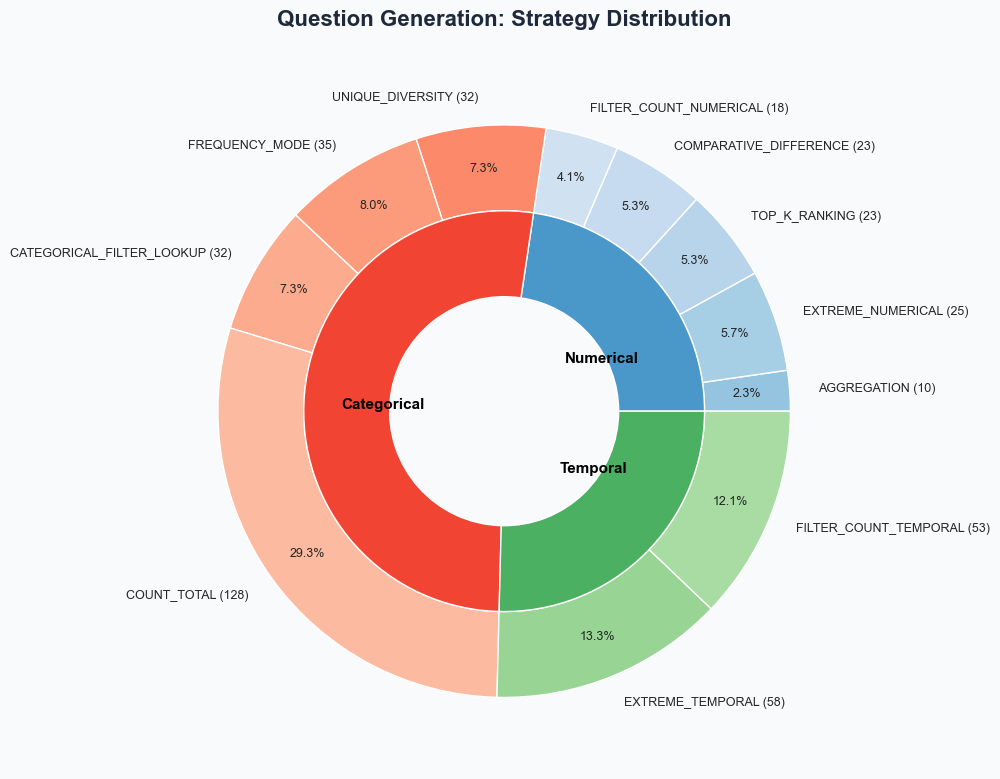

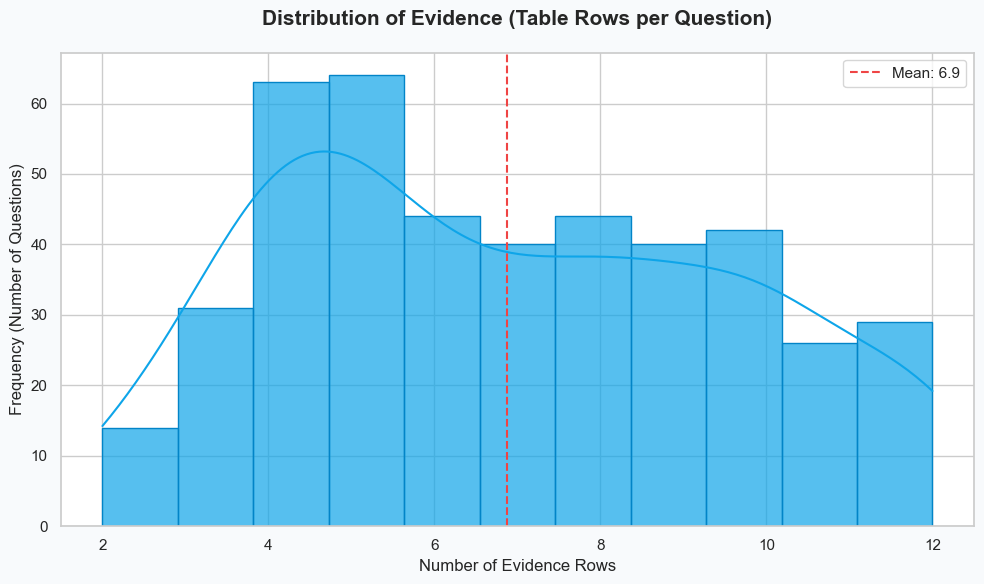

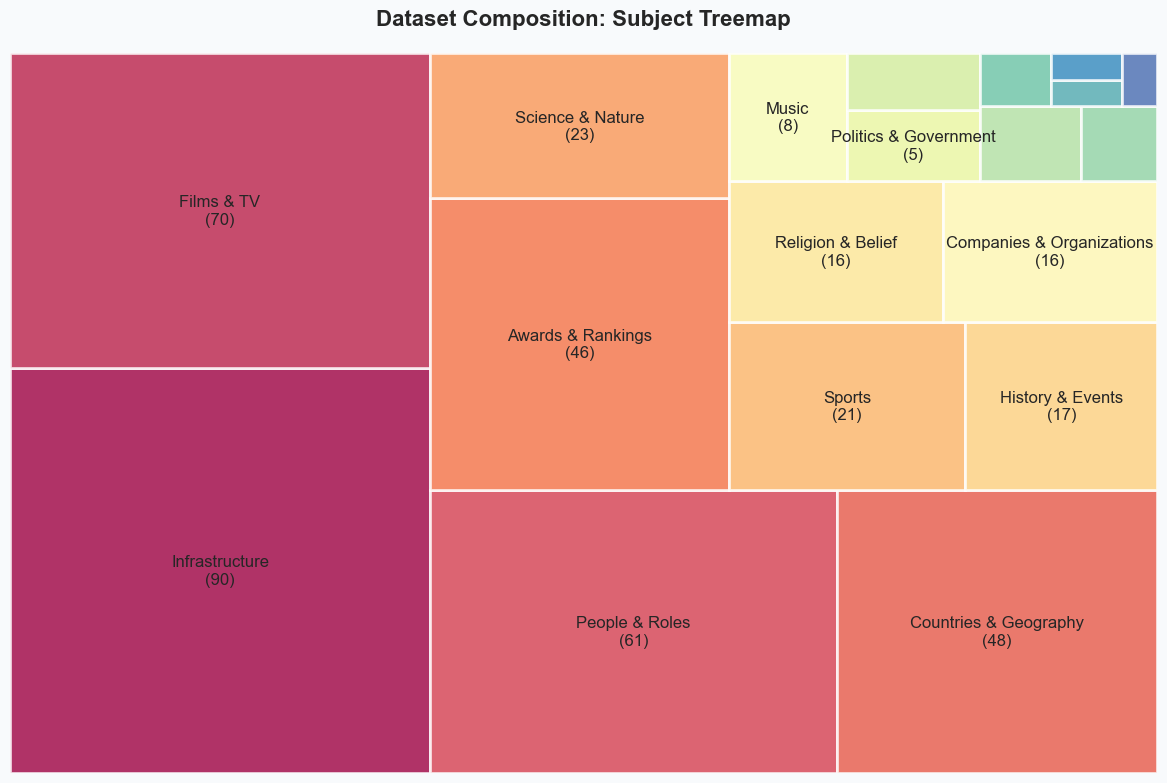

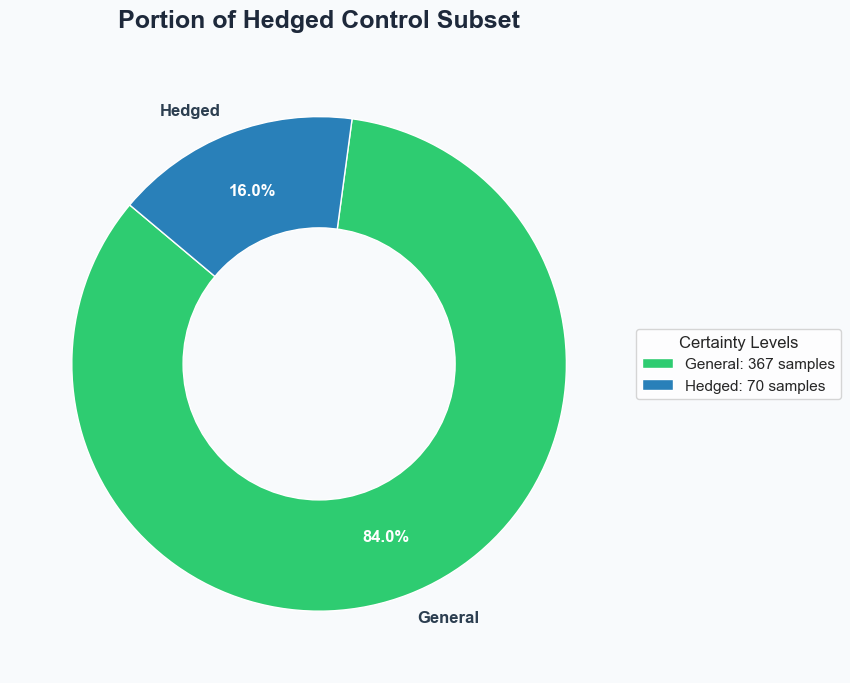

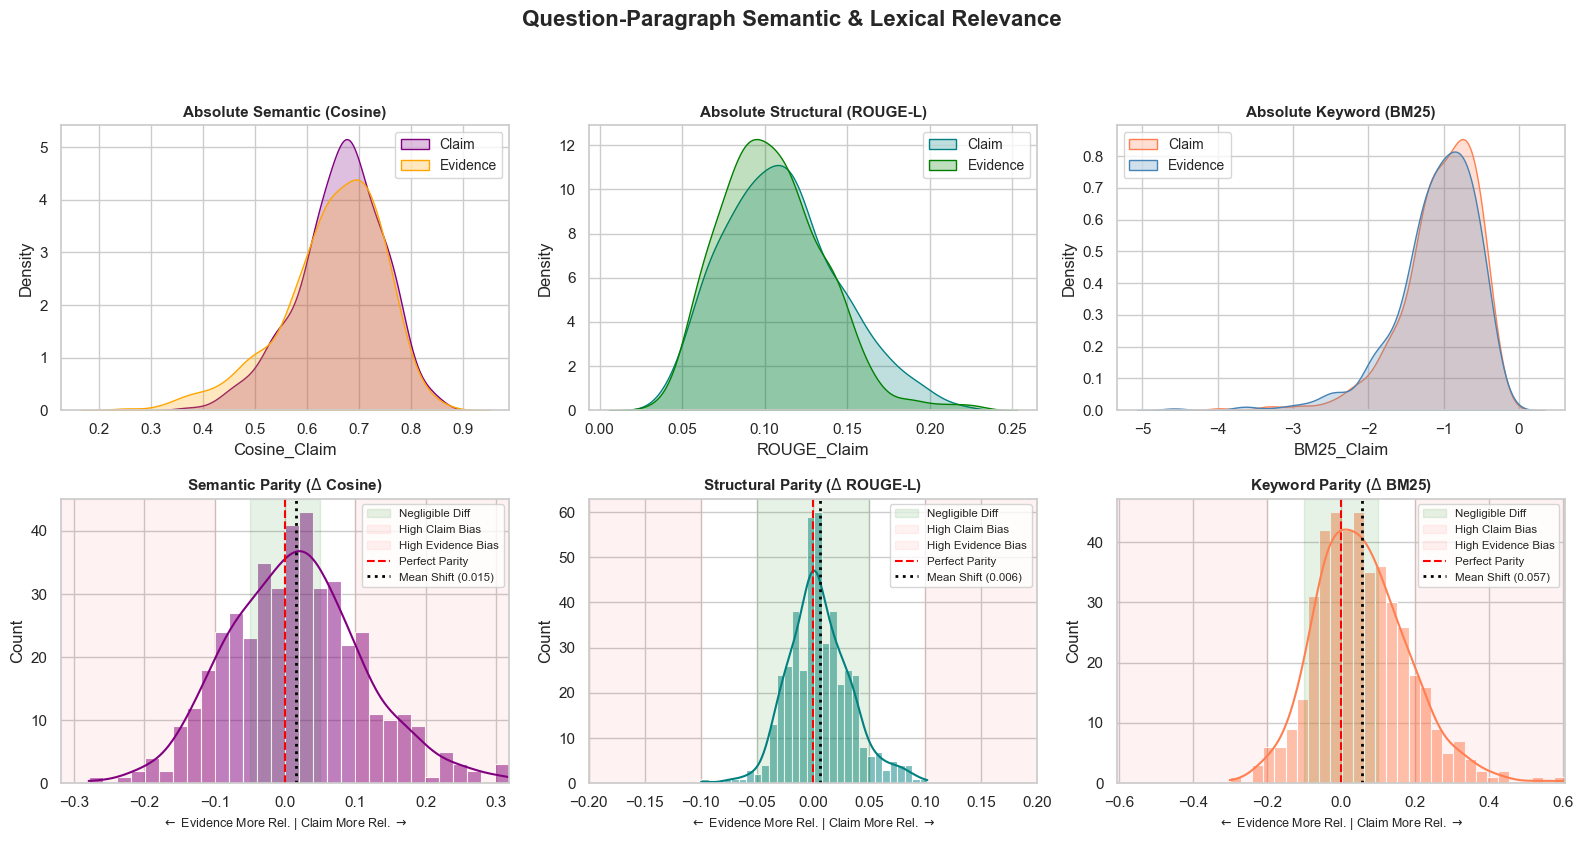

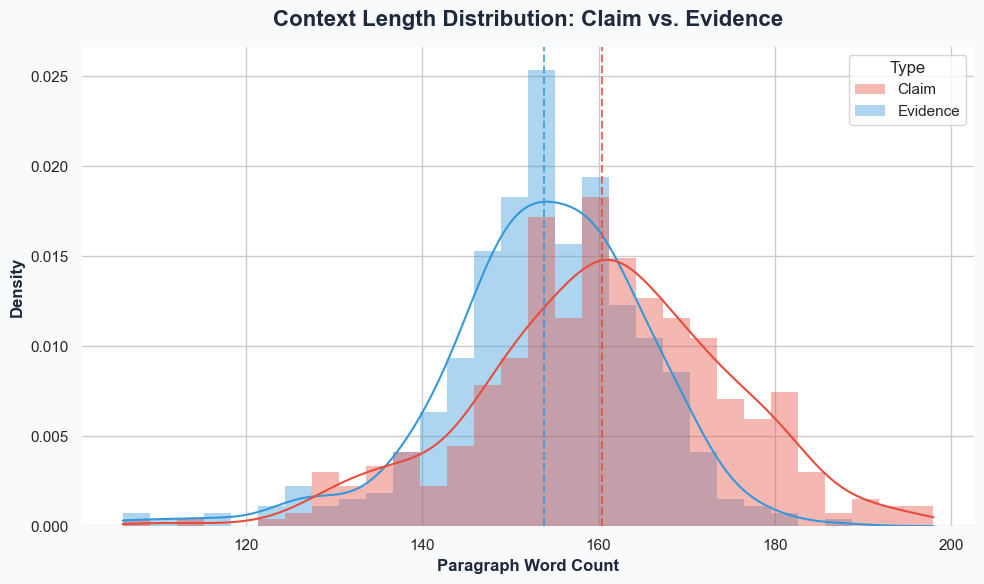

🔍 Displaying examples for 11 strategies...



In [107]:
stats_engine = KnowledgeConflictDatasetStats(load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions_full.json")),
                                             load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_paragraphs.json")))
await stats_engine.show_statistics()